In [1]:
import os 

import xarray as xr
import numpy as np
import pandas as pd 
import fnmatch
from numpy.polynomial import Polynomial
import seaborn as sns

import cartopy.feature as cf
import healpy as hp
import cftime
from datetime import datetime, timedelta
import pyproj
import regionmask
import scipy.stats as sstats
from scipy.interpolate import griddata
import xesmf as xe 
import cmocean as cmo 
import matplotlib.ticker as mticker

#import easygems.healpix as egh
#from scipy.spatial import KDTree
import matplotlib.tri as tri

import cmocean 
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import numpy as np
import matplotlib.gridspec as gridspec
from matplotlib import cm
from matplotlib.ticker import LinearLocator
from matplotlib.colors import Normalize

# import aqua
# from aqua import Reader
# from aqua import inspect_catalog
import pyproj
pyproj.datadir.set_data_dir("/home/bsc/bsc032263/.conda/envs/aqua/share/proj")

os.chdir("/home/b/b382291/git/small_islands")

from small_island_functions import interpolate_timeseries
from small_island_functions import adjust_lon_coords
from small_island_functions import island_bounds_box
from small_island_functions import format_data
from small_island_functions import matching_resolutions_xe
from small_island_functions import create_island_mask
from small_island_functions import create_ocean_mask

island_bounds = island_bounds_box()

!hostname

/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


l40067.lvt.dkrz.de


In [2]:
###################33 PRECIPITATION #####################################
#### import data from DestinE and from CORDEX

diff = 273.15 

root_noaa =  "/work/bb1153/b382291/caribbean/noaa_oisstv2"
root_esa = "/work/bb1153/b382291/caribbean/esa_sstcci"
root_ifs_nemo = "/work/bb1153/b382291/caribbean/IFS-NEMO/0.05"
root_ifs_fesom = "/work/bb1153/b382291/caribbean/IFS-FESOM/0.05"
root_icon = "/work/bb1153/b382291/caribbean/ICON/0.05"

# root_mswep = "/gpfs/scratch/bsc32/bsc032263/mswep"
# root_era5_land = "/gpfs/scratch/bsc32/bsc032263/era5land"
# root_cimh = "/gpfs/scratch/bsc32/bsc032263/cimh"

islands_all = ["caribbean_islands"] 
islands_all_short = ["car"] 

In [3]:

var = "tos"

###############################3 load observational data ###############################################
noaa_sst = xr.open_dataset(f"{root_noaa}/tos_1990_01_01_to_2019_03_31.nc")
noaa_sst = noaa_sst[f"sst"]

# want latitude to run from north to south
noaa_sst = noaa_sst.sortby("lat", ascending=False)
noaa_sst = adjust_lon_coords(noaa_sst)

# print and name variable 
var_name = f"noaa_{var}"
print('variable', {var_name})
globals()[var_name] = noaa_sst.drop_duplicates("time")

###############################3 load observational data ###############################################

esa_sst = xr.open_dataset(f"{root_esa}/tos_1990_01_to_2019_12_monthly_mean.nc")
esa_sst = esa_sst[f"{var}"]

# want latitude to run from north to south
esa_sst = esa_sst.sortby("lat", ascending=False)

# print and name variable 
var_name = f"esa_{var}"
print('variable', {var_name})
globals()[var_name] = esa_sst.drop_duplicates("time")

################################ load historical ClimateDT data ###############################################

var = "avg_tos"

# CURRENTLY REMOVING ICON AS MISSING 2014 
roots = [root_ifs_nemo, root_ifs_fesom, root_icon] #
names = ["nemo", "fesom", "icon"] #"fesom", 

for index, root in enumerate(roots):

    folder_path = f"{root}"
    # Define expected patterns explicitly
    pattern_1990 = f"{var}_1990*car_crop.nc"
    #pattern_2015 = f"{var}_2015*car_crop.nc"

    all_files = os.listdir(folder_path)

    files_1990 = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern_1990)
    ]
    # files_2015 = [
    #     os.path.join(folder_path, filename)
    #     for filename in all_files
    #     if fnmatch.fnmatch(filename, pattern_2015)
    # ]

    ds1 = xr.open_dataset(files_1990[0])
    ds = ds1.drop_duplicates("time")

    # ds2 = xr.open_dataset(files_2015[0])
    # ds2 = ds2.drop_duplicates("time")

    # ds = xr.concat([ds1, ds2], "time")
    # ds = ds.drop_duplicates("time")

    #rename to lat lon
    ds = ds.rename({'latitude':'lat'})
    ds = ds.rename({'longitude':'lon'})

    # want to use the - notatin
    ds = adjust_lon_coords(ds[f"{var}"])
    
    var_name = f"{names[index]}_tos"
    print('variable', {var_name})
    # adjusting to degree C 
    globals()[var_name] = ds - diff 



variable {'noaa_tos'}
variable {'esa_tos'}
variable {'nemo_tos'}
variable {'fesom_tos'}
variable {'icon_tos'}


# want to use the ESA dataset as that has the same resolution as the ClimateDT 

# re-calculating mean bias for islands 

In [4]:
islands_all = ["LUC","BAR","GRE", "TOB", "TRI"]

# Define datasets and titles
data_list_names = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos", "observations"] # "fesom_tos",

# Define datasets and titles
data_list = [noaa_tos, nemo_tos, fesom_tos, icon_tos] #fesom_tos,

#   "area":"15/-63/9/-58" # north/west/south/east
lats = [15,9]
lons = [-63, -58]

time_start = "1992"
time_end = "2014"

# reducing size of reference
reference = globals()["esa_tos"].sel(
                        lat = slice(lats[0], lats[1]), 
                        lon = slice(lons[0], lons[1])
                    )

cbar_max = 0
cbar_min = 100

to_plot_all = []

heat_map_all = np.zeros([len(islands_all), len(data_list)])
heat_map_all_rmse = np.zeros([len(islands_all), len(data_list)])

for indx_island, island in enumerate(islands_all):

    # get lat and lon of island 
    island_bounds = island_bounds_box()
    latitude, longitude = island_bounds[island]

    # extending the bounds slightly to avoid white edges while plotting 
    latitude[0] = latitude[0] - 0.2
    latitude[1] = latitude[1] + 0.2
    longitude[0] = longitude[0] - 0.2
    longitude[1] = longitude[1] + 0.2

    # going to take the mean across the 1992 - 2016 reference period
    reference_for = format_data(reference, 
                                "tos", 
                                island, 
                                time_start = time_start, 
                                time_end = time_end
                            )

    reference_for = create_ocean_mask(reference_for)

    for indx, data in enumerate(data_list):

        # making sure we're using the same 'big' domain
        data = data.sel(
                        lat = slice(lats[0], lats[1]), 
                        lon = slice(lons[0], lons[1])
                    )
    
        data = format_data(data, "tos", island)
        
        # MUST MASK model data BEFORE DOING THE RE-GRIDDING
        data = create_ocean_mask(data)

        # bringing the low res to the high res grid 
        # grid in, grid out, bringing everything to the resolution of the 
        # obs in thiscase. 
        data_match = matching_resolutions_xe(
            data, 
            reference_for, 
            method = 'bilinear'
        ) 

        if data.lat[2].values - data.lat[1].values < 0: 
            #era5 has backward lat data

            # original grid model data 
            # FOR THE PLOTTING
            data_crop = data.sel(
                lat = slice(latitude[1], latitude[0]), 
                lon = slice(longitude[0], longitude[1])
            )

        else: 
            # original grid model data 
            data_crop = data.sel(
                lat = slice(latitude[0], latitude[1]), 
                lon = slice(longitude[0], longitude[1])
            )
        
        # regridding model data to high res grid
        data_match_crop = data_match.sel(
            lat = slice(latitude[1], latitude[0]), 
            lon = slice(longitude[0], longitude[1])
        )

        # original grid observations
        reference_for_crop = reference_for.sel(
            lat = slice(latitude[1], latitude[0]), 
            lon = slice(longitude[0],longitude[1])
        )

        # re-gridded obs data
        # reference_match_crop = create_island_mask(reference_match_crop)
        
        # obs data on original grid
        #reference_for_crop = create_island_mask(reference_for_crop)

        cbar_max_temp0 = np.round(np.nanmax(data_crop), 2)
        cbar_min_temp0 = np.round(np.nanmin(data_crop), 2)

        cbar_max_temp2 = np.round(np.nanmax(reference_for_crop), 2)
        cbar_min_temp2 = np.round(np.nanmin(reference_for_crop), 2)

        cbar_max_temp = np.nanmax([cbar_max_temp0, cbar_max_temp2])
        cbar_min_temp = np.nanmin([cbar_min_temp0, cbar_min_temp2])


        if cbar_max_temp > cbar_max:
            cbar_max = cbar_max_temp
        if cbar_min_temp < cbar_min: 
            cbar_min = cbar_min_temp


        # compute mean bias 
        heat_map = (data_match_crop - reference_for_crop).mean(skipna=True).values # /reference_match_crop.mean(skipna=True).values
        heat_map_all[indx_island, indx] = heat_map
        var_name = f"{data_list_names[indx]}_{island}_heat_map"
        globals()[f"{var_name}"] = heat_map

        # compute RMSE 
        heat_map_rmse = np.sqrt(((data_match_crop - reference_for_crop)**2).mean(skipna=True).values)
        heat_map_all_rmse[indx_island, indx] = heat_map_rmse
        var_name = f"{data_list_names[indx]}_{island}_heat_map_rmse"
        globals()[f"{var_name}"] = heat_map_rmse

            # compute RMSE 
            #rmse = np.sqrt(((data_crop - reference_match)**2).mean(skipna=True).values)
            #heat_map[indx_island, indx] = (rmse / reference_match.mean(skipna=True))*100
            
        # creating final 
        var_name = f"{data_list_names[indx]}_{island}_maps"
        globals()[f"{var_name}"] = data_crop

        # adding the reference to the end of each list
        if indx == len(data_list) - 1:
            var_name = f"{data_list_names[indx+1]}_{island}_maps"
            globals()[f"{var_name}"] = reference_for_crop


        ### if you want to plot how the re-gridded obs look ###             
        # creating final 
        var_name = f"{data_list_names[indx]}_{island}_regridded_model_maps"
        globals()[f"{var_name}"] = data_match_crop

        #to_plot_all.append(data)

        # adding the reference to the end of each list
        if indx == len(data_list) - 1:
            var_name = f"{data_list_names[indx+1]}_{island}_regridded_model_maps"
            globals()[f"{var_name}"] = reference_for_crop

            #to_plot_all.append(reference_for_crop)
    
    # round to whole numbers
    cbar_max_ci_r = np.ceil(cbar_max)
    cbar_min_ci_r = np.floor(cbar_min)
    cbar_max_mi_r = np.ceil(cbar_max)
    cbar_min_mi_r = np.floor(cbar_min)

/home/b/b382291/git/small_islands/small_island_functions.py:235: UserWarning: `natural_earth_v5_0_0.ocean_basins_50` does not quite extend to 180°E - it's recommended to use `natural_earth_v5_1_2.ocean_basins_50` instead. See https://github.com/regionmask/regionmask/issues/410.
  basins = regionmask.defined_regions.natural_earth_v5_0_0.ocean_basins_50


In [7]:
np.nanmin(heat_map_all)/2

np.float64(-1.1609456835674878)

true
true
true
true
true


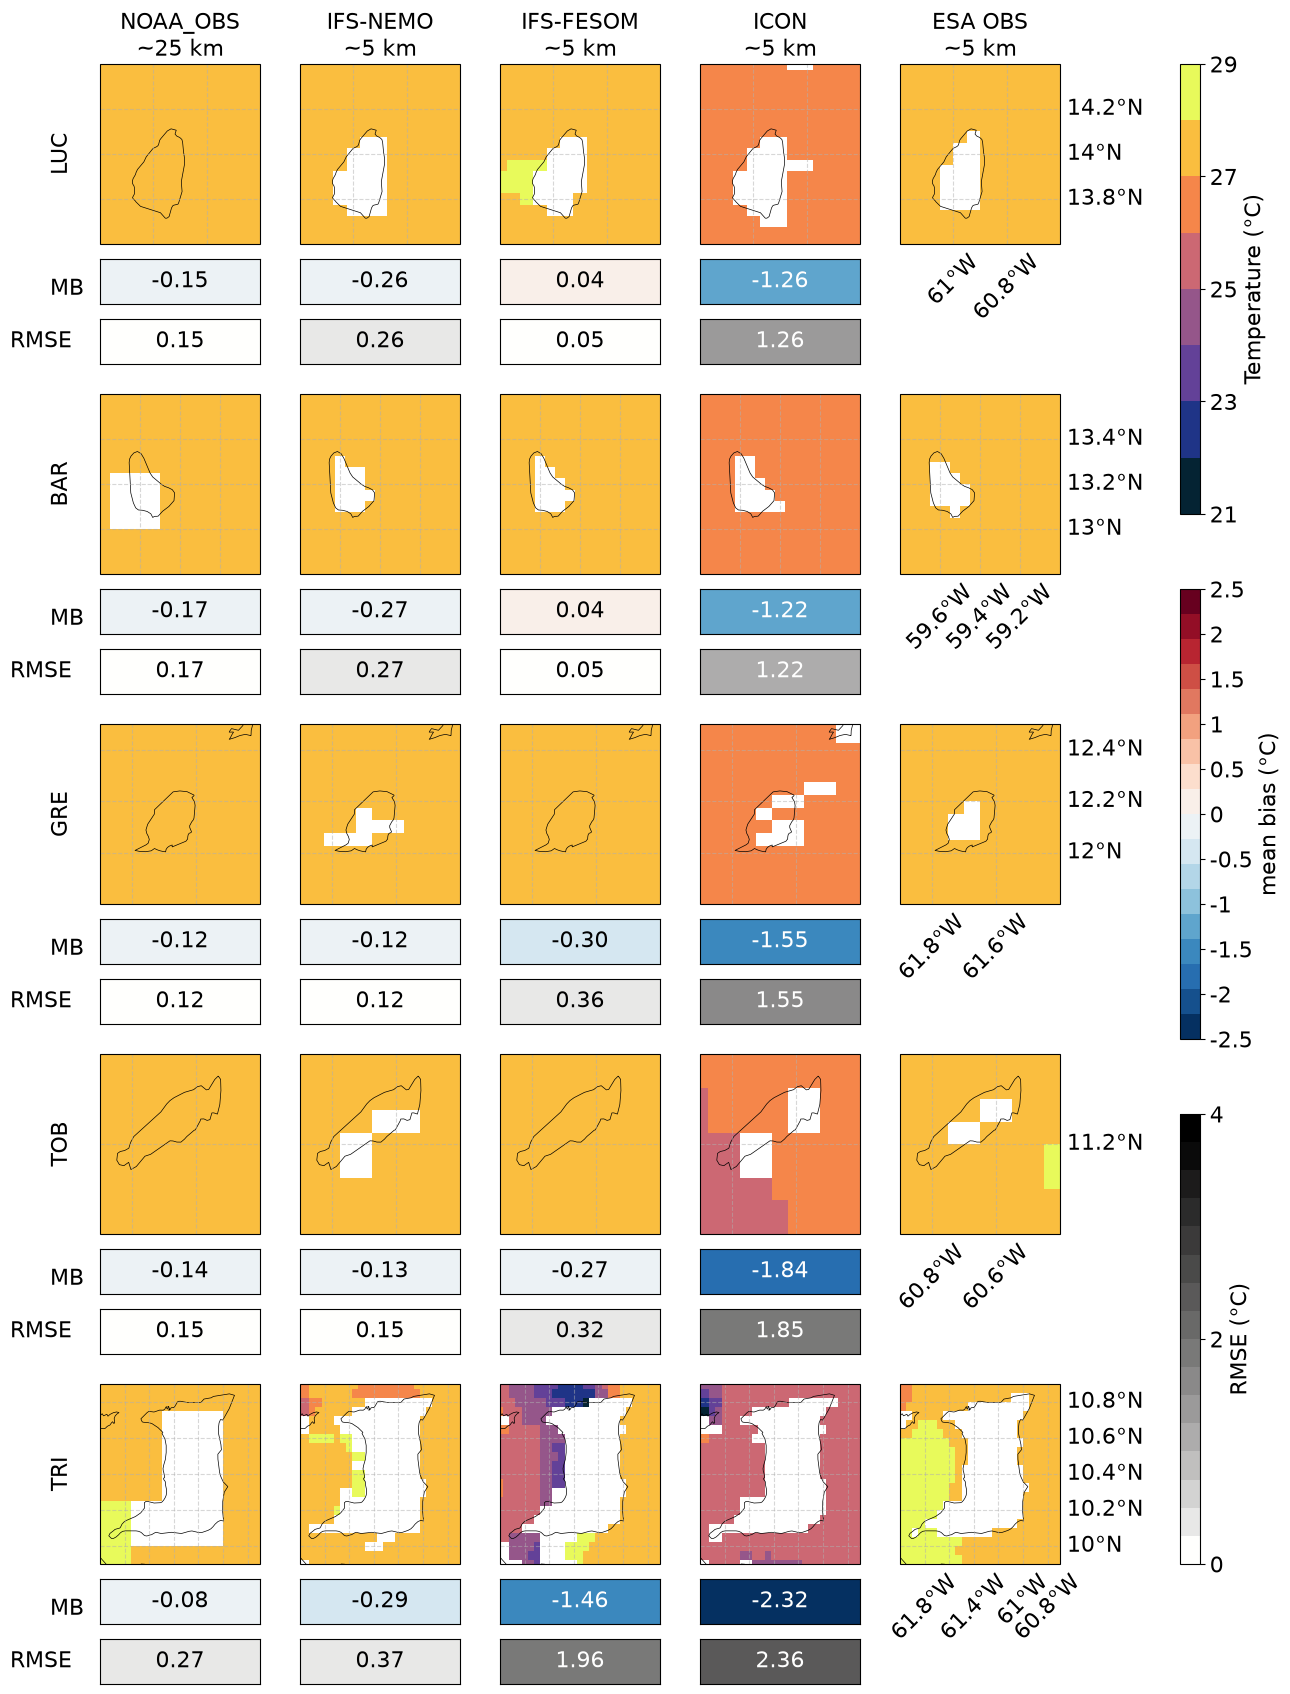

In [8]:
projection = ccrs.PlateCarree()
fsize = 16


data_list_names = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos", "observations"] # "fesom_tos",

######### creating the  plot ##############
titles = ["NOAA_OBS\n~25 km",
          "IFS-NEMO\n~5 km",
          "IFS-FESOM\n~5 km", 
          "ICON\n~5 km",
          "ESA OBS\n~5 km"] 

# plus 1 for obs
n_models = len(data_list) + 1
n_islands = len(islands_all)

fig = plt.figure(figsize=(2* n_models, 3* n_islands))

map_height = 0.6 / n_islands  # 80% of row height
heat_height = 0.15 / n_islands  # 20% of row heigh
col_width = 0.8 / n_models

if var == "pr":
    label1 = "Precipitation\nLa Reunion island (mm / hr)"
    label2 = "Precipitation\nCanary islands (mm / hr)"
    cmap = cmocean.cm.rain
elif var == "avg_tos":
    label1 = "Temperature (°C)"
    cmap = cmocean.cm.thermal

cbar_max = np.max([cbar_max_ci_r , cbar_max_mi_r ])
cbar_min = np.max([cbar_min_ci_r , cbar_min_mi_r ])

cmap = cmap(np.linspace(0, 1, int(cbar_max - cbar_min)))
cmap = ListedColormap(cmap)


if var == "avg_tos":
    cmap_heatmap = plt.get_cmap("RdBu_r")
elif var == "pr":
    cmap_heatmap = plt.get_cmap("RdBu")
    
cmap_heatmap = cmap_heatmap(np.linspace(0, 1, 18))
cmap_heatmap = ListedColormap(cmap_heatmap)

cmap_heatmap_rmse = cmocean.cm.gray_r # plt.get_cmap("Blues")
cmap_heatmap_rmse = cmap_heatmap_rmse(np.linspace(0, 1, 16))
cmap_heatmap_rmse = ListedColormap(cmap_heatmap_rmse)
count = 0

for i, island in enumerate(islands_all):

    island_bounds = island_bounds_box()
    latitude, longitude = island_bounds[island]

    for j, data in enumerate(data_list_names):

        # Compute subplot positions
        x0 = j * (1/n_models)
        y_map = 1.0 - (i + 1) * (map_height + 2*heat_height + 0.04)
        # Create map axis
        ax_map = fig.add_axes([x0, y_map, col_width, map_height], projection=projection)

        to_plot = globals()[f"{data_list_names[j]}_{island}_maps"]
 
        lons, lats = np.meshgrid(to_plot.lon.values, to_plot.lat.values)

        # if island == "REU":
        #     pcm_mi = ax_map.pcolormesh(lons, lats, to_plot, 
        #   transform=projection, cmap = cmap, shading='auto',
        #                         vmin=cbar_min_mi, vmax=cbar_max_mi)
        # else:
        pcm = ax_map.pcolormesh(lons, lats, to_plot, transform=projection, 
                                cmap = cmap, shading='auto',
                                vmin=cbar_min, vmax=cbar_max
                                )
        

        ax_map.set_extent([longitude[0], longitude[1], latitude[0], latitude[1]], crs=projection)
        ax_map.set_aspect('auto')  # <- this is the key
        ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

        gl = ax_map.gridlines(draw_labels = False, linestyle='dashed',alpha=0.5) 
        #Draws meridians and parallels.
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 0.2))  # adjust step as needed
        gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 0.2))    # adjust step as needed
        
        if j == len(data_list_names) - 1:

            gl.bottom_labels = True
            gl.right_labels = True
            # Increase the font size of the gridline labels
            gl.xlabel_style = {'size': fsize, 'rotation':45}
            gl.ylabel_style = {'size': fsize}
            # draw every other meridian / parallel


        # ADDING IN RMSE AND MEAN BIAS 
        if j < len(data_list_names) - 1:

            # Create heatmap axis
            y_heat = y_map - heat_height - 0.01  # heatmap is on top


            heat_map = globals()[f"{data_list_names[j]}_{island}_heat_map"]

            ax_heat = fig.add_axes([x0, y_heat, col_width, heat_height])
            hcm = ax_heat.pcolormesh([[heat_map]], cmap=cmap_heatmap,
                            vmin=-2.5, # np.nanmax(np.abs(heat_map_all)), 
                            vmax=2.5) # np.nanmax(np.abs(heat_map_all))) # ,
                            #shading='auto')

            # Add the value in the center of the cell
            if heat_map < np.nanmin(heat_map_all)/2 or heat_map > -np.nanmin(heat_map_all)/2:
                ax_heat.text(0.5, 0.5, f"{heat_map:.2f}",  # format with 2 decimal places
                ha='center', va='center',
                fontsize=fsize, color='white')
            else:
                ax_heat.text(0.5, 0.5, f"{heat_map:.2f}",  # format with 2 decimal places
                    ha='center', va='center',
                    fontsize=fsize, color='black')

            # Keep the axis frame (box)
            ax_heat.tick_params(
                left=False,    
                bottom=False,  
                labelleft=False,
                labelbottom=False 
            )

            # Create heatmap axis for RMSE
            y_heat_rmse = y_map - heat_height - 0.05  # heatmap is on top
            heat_map_rmse = globals()[f"{data_list_names[j]}_{island}_heat_map_rmse"]

            ax_heat_rmse = fig.add_axes([x0, y_heat_rmse, col_width, heat_height])
            hcm_rmse = ax_heat_rmse.pcolormesh([[heat_map_rmse]], cmap=cmap_heatmap_rmse,  
                            vmin= 0,
                            vmax=4) # np.round(np.nanmax(np.abs(heat_map_all_rmse)),0)) 
                            
            # Add the value in the center of the cell
            if heat_map_rmse > np.nanmax(heat_map_all_rmse)/2:
                ax_heat_rmse.text(0.5, 0.5, f"{heat_map_rmse:.2f}",  # format with 2 decimal places
                ha='center', va='center',
                fontsize=fsize, color='white')
            else:
                ax_heat_rmse.text(0.5, 0.5, f"{heat_map_rmse:.2f}",  # format with 2 decimal places
                ha='center', va='center',
                fontsize=fsize, color='black')

            # Keep the axis frame (box)
            ax_heat_rmse.tick_params(
                left=False,    
                bottom=False,  
                labelleft=False,
                labelbottom=False 
            )



        # Optional: Add titles/labels
        if j == 0:
            fig.text(-0.05, y_map + map_height / 2, island, va='center', 
                     rotation = 90, fontsize=fsize)
            fig.text(-0.05, y_map + map_height / 2 - 0.09, "MB", va='center', fontsize=fsize)
            fig.text(-0.09, y_map + map_height / 2 - 0.125 , "RMSE", va='center', fontsize=fsize)


        if i == 0:
            print('true')
            ax_map.set_title(titles[j], fontsize=fsize)
        
        count += 1

cbar_ax = fig.add_axes([1.08, 0.6, 0.02, 0.3])
cbar = fig.colorbar(pcm, cax=cbar_ax, orientation = "vertical", shrink = 0.5)

ticks = [29,27, 25,23, 21]
cbar.ax.set_yticks(ticks)
cbar.ax.set_yticklabels([str(t) for t in ticks])

cbar.ax.tick_params(labelsize=fsize)         # Tick labels
cbar.set_label(label=label1, fontsize = fsize)


# for mean bais 
cbar_ax = fig.add_axes([1.08, 0.25, 0.02, 0.3])
cbar = fig.colorbar(hcm, cax = cbar_ax, orientation='vertical', shrink=0.5)
ticks = [-2.5, -2 , -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5]
cbar.ax.set_yticks(ticks)
cbar.ax.set_yticklabels([str(t) for t in ticks])
cbar.ax.tick_params(labelsize=fsize)         # Tick labels
cbar.set_label(label="mean bias (°C)", fontsize = fsize)


# for RMSE
cbar_ax = fig.add_axes([1.08, -0.1, 0.02, 0.3])     
cbar = fig.colorbar(hcm_rmse, cax = cbar_ax, orientation='vertical', shrink=0.5)
ticks = [4, 2 , 0]
cbar.ax.set_yticks(ticks)
cbar.ax.set_yticklabels([str(t) for t in ticks])
cbar.ax.tick_params(labelsize=fsize)         # Tick labels
cbar.set_label(label="RMSE (°C)", fontsize = fsize)
plt.show()
